In [4]:
import sys
sys.path.append("..")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

model = joblib.load("../models/lightgbm_v2_calibrated.joblib")
prep = model.pipeline.named_steps["prep"]
lgbm = model.pipeline.named_steps["model"]

test = pd.read_parquet("../data/processed/test.parquet")
sample = test.sample(n=5000, random_state=42)
X_sample = sample.drop(columns=["target"])

X_ready = prep.transform(X_sample)
p_sample = model.predict_proba(X_sample)[:, 1]

print(X_ready.shape)

(5000, 62)


In [5]:
explainer = shap.TreeExplainer(lgbm)
shap_values = explainer(X_ready)

if shap_values.values.ndim == 3:
    shap_values = shap_values[:, :, 1]

print(shap_values.values.shape)

(5000, 62)


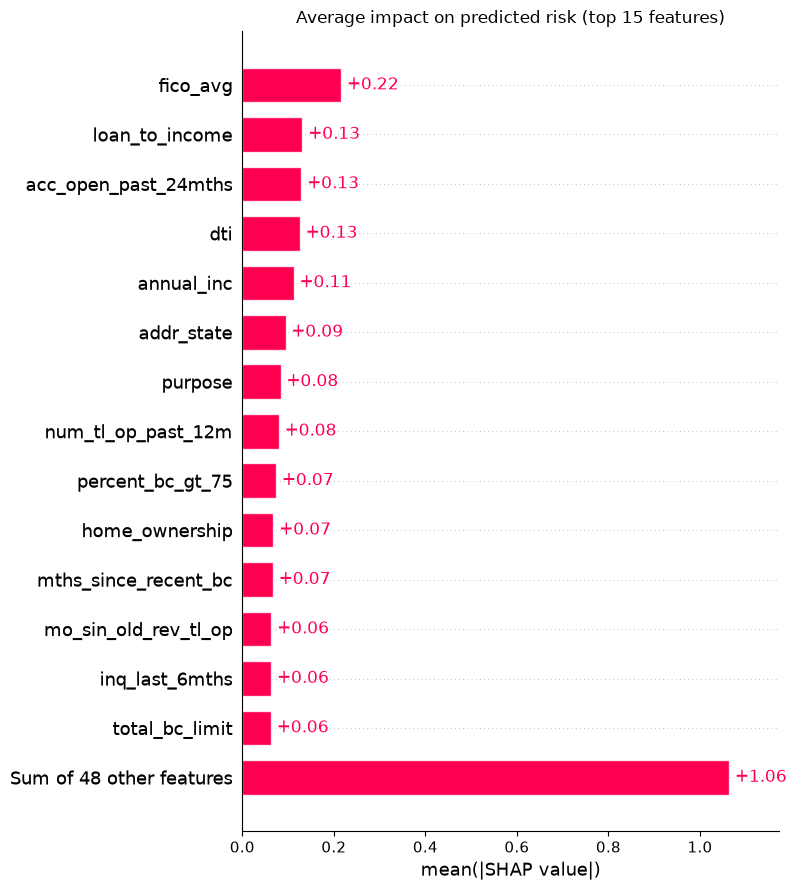

In [6]:
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title("Average impact on predicted risk (top 15 features)")
plt.tight_layout()
plt.savefig("../results/figures/shap_importance.png", dpi=120, bbox_inches="tight")
plt.show()

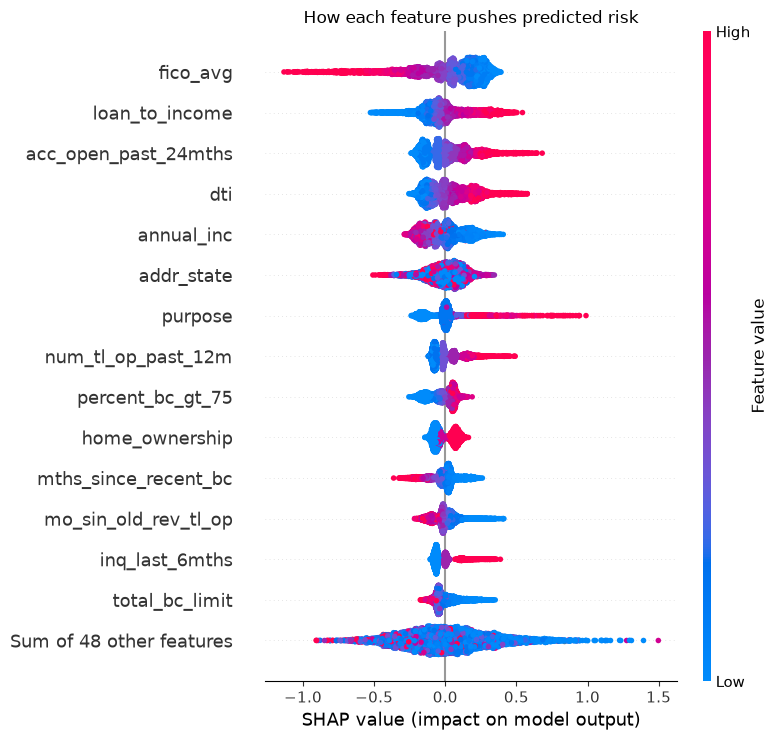

In [7]:
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("How each feature pushes predicted risk")
plt.tight_layout()
plt.savefig("../results/figures/shap_beeswarm.png", dpi=120, bbox_inches="tight")
plt.show()

Riskiest applicant: predicted risk 64.4% (actually repaid)


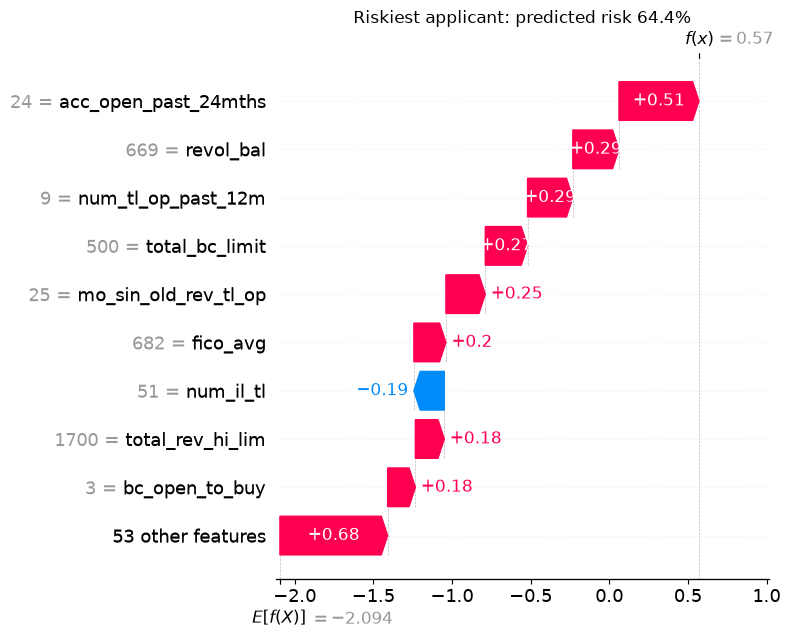

Safest applicant: predicted risk 0.6% (actually repaid)


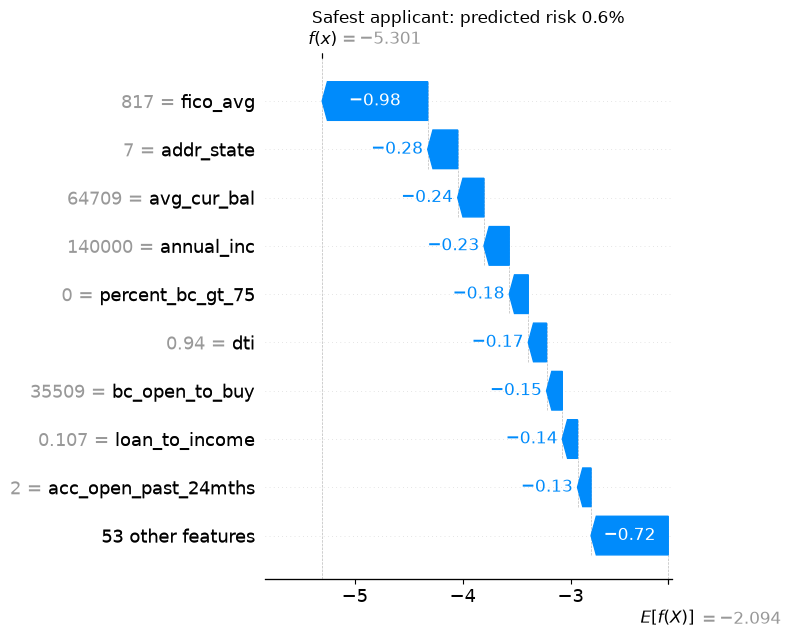

In [8]:
riskiest = int(np.argmax(p_sample))
safest = int(np.argmin(p_sample))

for label, i in [("Riskiest", riskiest), ("Safest", safest)]:
    actual = "defaulted" if sample["target"].iloc[i] == 1 else "repaid"
    print(f"{label} applicant: predicted risk {p_sample[i] * 100:.1f}% (actually {actual})")
    shap.plots.waterfall(shap_values[i], max_display=10, show=False)
    plt.title(f"{label} applicant: predicted risk {p_sample[i] * 100:.1f}%")
    plt.tight_layout()
    plt.savefig(f"../results/figures/shap_waterfall_{label.lower()}.png", dpi=120, bbox_inches="tight")
    plt.show()

In [9]:
from src.explain import make_explainer, explain_applicant
from src.policy import load_policy, decide

policy = load_policy("../results/policy.json")
app_explainer = make_explainer(model)

applicant = X_sample.iloc[[riskiest]]
probability = model.predict_proba(applicant)[:, 1][0]
decision = decide(probability, policy["cutoff"], policy["review_margin"])

print(f"Predicted risk: {probability * 100:.1f}%  →  Decision: {decision}")
explain_applicant(model, app_explainer, applicant)

Predicted risk: 64.4%  →  Decision: Reject


c:\Users\Administrator\loan-default-project\.venv\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


,feature,value,contribution,effect
0,acc_open_past_24mths,24.0,0.508675,raises risk
1,revol_bal,669.0,0.293330,raises risk
2,num_tl_op_past_12m,9.0,0.287749,raises risk
3,total_bc_limit,500.0,0.268913,raises risk
4,mo_sin_old_rev_tl_op,25.0,0.250396,raises risk
